# CSE457 — BÁO CÁO THỰC HÀNH LAB 3
## NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI GAUSSIAN HMM
- **Sinh viên:** Lê Văn Chương
- **MSSV:** 2351260643
- **Trường:** Đại học Thủy Lợi — Khoa Công nghệ Thông tin (Bộ môn Trí tuệ Nhân tạo)

---
### Mục tiêu thực hành:
1. Xây dựng vector đặc trưng 39 chiều (13 MFCC tĩnh + 13 Delta + 13 Delta-Delta) và chuẩn hóa CMVN.
2. Thiết kế và huấn luyện mô hình Markov ẩn (HMM) cấu trúc trái-sang-phải (Left-to-Right) 5 trạng thái với phân bố phát xạ Gaussian đa chiều (Diagonal covariance).
3. Đánh giá nhận dạng Maximum Likelihood, giải mã đường trạng thái Viterbi alignment.
4. Đối sánh hiệu năng định lượng với giải thuật DTW baseline từ Lab 2.
5. Xây dựng từ điển phát âm Lexicon và mô hình ngôn ngữ Bigram với MAP Re-ranking.
6. Thử nghiệm tính bền vững (Robustness) với nhiễu và thiết lập ngưỡng từ chối mẫu lạ (Reject threshold).


In [1]:
import time, pickle, math, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import librosa
import matplotlib.pyplot as plt
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

warnings.filterwarnings("ignore")
SR = 16000
DATA = Path("dataset")
LABELS = ["mo", "dong", "len", "xuong", "dung"]
Path("figures").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
print("Khởi tạo môi trường thành công!")
print(f"- Tần số lấy mẫu: {SR} Hz")
print(f"- Danh sách nhãn ({len(LABELS)} từ): {LABELS}")


Khởi tạo môi trường thành công!
- Tần số lấy mẫu: 16000 Hz
- Danh sách nhãn (5 từ): ['mo', 'dong', 'len', 'xuong', 'dung']


## A. Chuẩn hóa dữ liệu & Trích đặc trưng 39 chiều (MFCC + $\Delta$ + $\Delta^2$)
- Cắt khoảng lặng hai đầu bằng `librosa.effects.trim(y, top_db=30)`.
- Tiền nhấn (pre-emphasis) hệ số $\alpha = 0.97$.
- Trích xuất 13 MFCC cơ sở (khung 25 ms, bước nhảy 10 ms, Hamming window, 26 dải lọc mel).
- Tính đặc trưng động bậc 1 ($\Delta$) và bậc 2 ($\Delta^2$) ghép thành vector $T \times 39$.
- Chuẩn hóa trung bình và phương sai CMVN theo từng utterance.


In [2]:
def load_wav(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)          # endpoint detection
    return librosa.effects.preemphasis(y, coef=0.97)

def feat_from_signal(y, dynamic=True):
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=512,
                                win_length=int(0.025 * SR), hop_length=int(0.010 * SR),
                                window="hamming", n_mels=26, fmin=20, fmax=SR / 2)
    if dynamic:
        d1 = librosa.feature.delta(mfcc, order=1)
        d2 = librosa.feature.delta(mfcc, order=2)
        F = np.vstack([mfcc, d1, d2]).T                 # T x 39
    else:
        F = mfcc.T                                      # T x 13
    mu = F.mean(0, keepdims=True)                       # CMVN theo utterance
    sd = F.std(0, keepdims=True) + 1e-8
    return (F - mu) / sd

def load_split(split, dynamic=True, noise_snr=None, seed=0):
    rng = np.random.default_rng(seed)
    X, y, names = [], [], []
    for lab in LABELS:
        for wav in sorted((DATA / split / lab).glob("*.wav")):
            sig = load_wav(str(wav))
            if noise_snr is not None:
                p = np.mean(sig ** 2)
                n = rng.normal(0, np.sqrt(p / 10 ** (noise_snr / 10)), len(sig))
                sig = sig + n
            X.append(feat_from_signal(sig, dynamic)); y.append(lab); names.append(wav.name)
    return X, y, names

Xtr, ytr, ntr = load_split("train")
Xte, yte, nte = load_split("test")
print(f"Số lượng mẫu: Train = {len(Xtr)} (6 mẫu/lớp) | Test = {len(Xte)} (2 mẫu/lớp)")
print(f"Kích thước đặc trưng các mẫu đầu: {[F.shape for F in Xtr[:3]]} (chiều 2 = 39)")
leakage = bool(set(ntr) & set(nte))
print("Kiểm tra rò rỉ dữ liệu (leakage between train & test):", "PHÁT HIỆN LỖI" if leakage else "KHÔNG RÒ RỈ (HỢP LỆ)")


Số lượng mẫu: Train = 30 (6 mẫu/lớp) | Test = 10 (2 mẫu/lớp)
Kích thước đặc trưng các mẫu đầu: [(99, 39), (121, 39), (111, 39)] (chiều 2 = 39)
Kiểm tra rò rỉ dữ liệu (leakage between train & test): KHÔNG RÒ RỈ (HỢP LỆ)


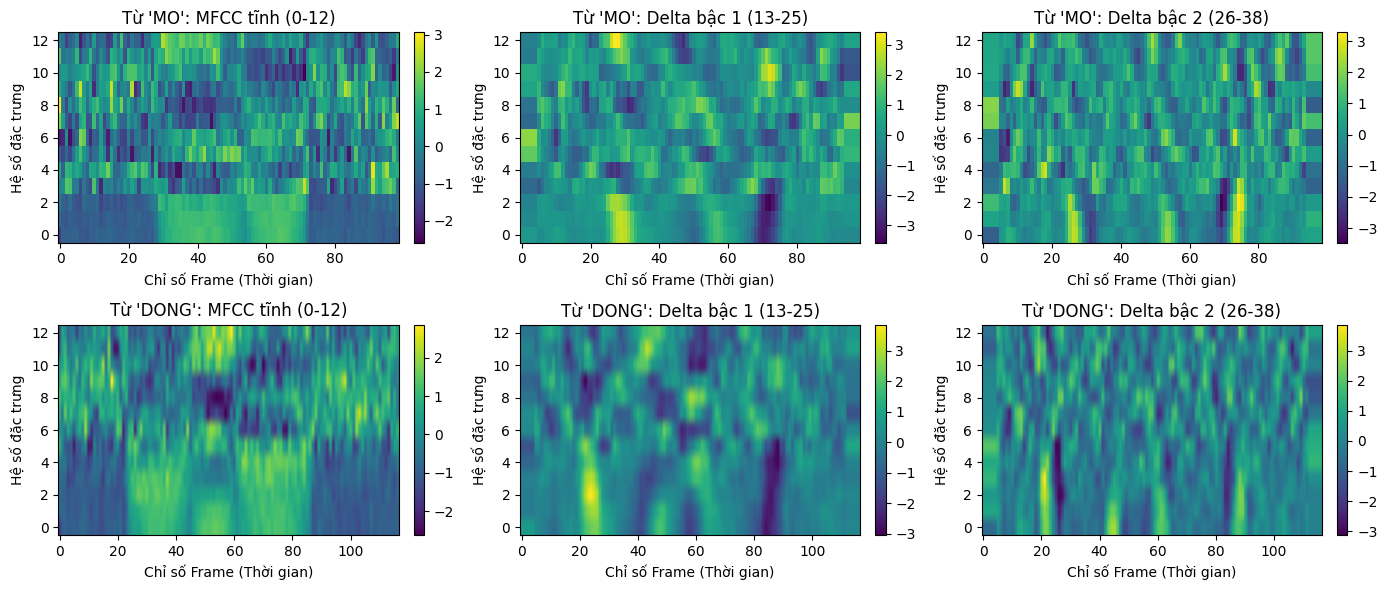

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for r, w in enumerate(["mo", "dong"]):
    wav = sorted((DATA / "train" / w).glob("*.wav"))[0]
    F = feat_from_signal(load_wav(str(wav)))
    for c, (nm, sl) in enumerate([("MFCC tĩnh (0-12)", slice(0, 13)), 
                                  ("Delta bậc 1 (13-25)", slice(13, 26)), 
                                  ("Delta bậc 2 (26-38)", slice(26, 39))]):
        im = ax[r, c].imshow(F[:, sl].T, aspect="auto", origin="lower", cmap="viridis")
        ax[r, c].set_title(f"Từ '{w.upper()}': {nm}")
        ax[r, c].set_xlabel("Chỉ số Frame (Thời gian)")
        ax[r, c].set_ylabel("Hệ số đặc trưng")
        fig.colorbar(im, ax=ax[r, c], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("figures/heatmaps.png", dpi=130)
plt.show()


## B. Khởi tạo mô hình Left-to-Right Gaussian HMM
- Cấu trúc trái-sang-phải (Left-to-Right) 5 trạng thái.
- Phân bố ban đầu: $\pi = [1, 0, 0, 0, 0]$ (bắt đầu tại trạng thái đầu tiên).
- Khởi tạo ma trận chuyển tiếp: $a_{ii} = 0.7, a_{i, i+1} = 0.3$, trạng thái cuối cùng là trạng thái hấp thụ ($a_{NN} = 1.0$).
- Kế thừa `GaussianHMM` để bảo toàn trạng thái hấp thụ và cấu trúc Left-to-Right sau mỗi M-step.


In [4]:
class LRGaussianHMM(GaussianHMM):
    """GaussianHMM duy trì trạng thái hấp thụ cuối cùng (a_NN=1) sau mỗi bước M-step."""
    def _do_mstep(self, stats):
        super()._do_mstep(stats)
        A = np.nan_to_num(self.transmat_)
        A[-1, :] = 0.0
        A[-1, -1] = 1.0
        for i in range(len(A) - 1):
            s = A[i].sum()
            if s <= 0:
                A[i, i], A[i, i + 1] = 0.7, 0.3
            else:
                A[i] /= s
        self.transmat_ = A

def make_lr_hmm(n_states=5, n_iter=80, cov="diag"):
    m = LRGaussianHMM(n_components=n_states, covariance_type=cov, n_iter=n_iter, tol=1e-3,
                      min_covar=1e-3, init_params="", params="tmc", random_state=0)
    start = np.zeros(n_states); start[0] = 1.0
    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i], A[i, i + 1] = 0.7, 0.3
    A[-1, -1] = 1.0
    m.startprob_, m.transmat_ = start, A
    return m

def check_topology(m):
    A = m.transmat_
    n = len(A)
    bad = [(i, j) for i in range(n) for j in range(n) if (j < i or j > i + 1) and A[i, j] > 1e-8]
    return bad


## C. Huấn luyện mô hình whole-word HMM (Baum-Welch EM)
- Khởi tạo Flat start (Uniform segmentation): Chia đều frame của từng utterance cho $N$ trạng thái để tính mean và covariance ban đầu, đảm bảo bảo toàn tính tuần tự thời gian.
- Nối các utterance thành ma trận $X$ lớn kèm mảng `lengths` truyền vào hàm `fit()`.
- Giám sát trạng thái hội tụ `monitor_.converged` và lưu các model ra `models/*.pkl`.


In [5]:
def flat_start(m, feats, cov="diag", floor=1e-2):
    n = m.n_components
    segs = [[] for _ in range(n)]
    for F in feats:
        for i, part in enumerate(np.array_split(F, n)):
            segs[i].append(part)
    D = feats[0].shape[1]
    means = np.zeros((n, D))
    covars = np.zeros((n, D)) if cov == "diag" else np.zeros((n, D, D))
    for i in range(n):
        S = np.vstack(segs[i])
        means[i] = S.mean(0)
        if cov == "diag":
            covars[i] = np.maximum(S.var(0), floor)
        else:
            covars[i] = np.cov(S.T) + floor * np.eye(D) if len(S) > D else np.eye(D)
    m.means_ = means
    m.covars_ = covars

def train_models(Xtr, ytr, n_states=5, dynamic=True, cov="diag", verbose=False):
    models = {}
    for lab in LABELS:
        feats = [f for f, l in zip(Xtr, ytr) if l == lab]
        X = np.vstack(feats); lengths = [len(f) for f in feats]
        m = make_lr_hmm(n_states, cov=cov)
        flat_start(m, feats, cov)
        m.fit(X, lengths)
        models[lab] = m
        if verbose:
            print(f"[{lab.upper():6s}] Hội tụ: {m.monitor_.converged} | Vi phạm topology: {check_topology(m)}")
            print("Ma trận A:", np.round(m.transmat_, 3))
    return models

t0 = time.time()
models = train_models(Xtr, ytr, 5, verbose=True)
t_hmm_train = time.time() - t0
for k, m in models.items():
    pickle.dump(m, open(f"models/{k}.pkl", "wb"))
print(f"\nHuấn luyện xong 5 mô hình trong {t_hmm_train:.2f} giây.")


[MO    ] Hội tụ: True | Vi phạm topology: []
Ma trận A: [[0.972 0.028 0.    0.    0.   ]
 [0.    0.867 0.133 0.    0.   ]
 [0.    0.    0.974 0.026 0.   ]
 [0.    0.    0.    0.867 0.133]
 [0.    0.    0.    0.    1.   ]]
[DONG  ] Hội tụ: True | Vi phạm topology: []
Ma trận A: [[0.968 0.032 0.    0.    0.   ]
 [0.    0.875 0.125 0.    0.   ]
 [0.    0.    0.973 0.027 0.   ]
 [0.    0.    0.    0.966 0.034]
 [0.    0.    0.    0.    1.   ]]
[LEN   ] Hội tụ: True | Vi phạm topology: []
Ma trận A: [[0.969 0.031 0.    0.    0.   ]
 [0.    0.867 0.133 0.    0.   ]
 [0.    0.    0.973 0.027 0.   ]
 [0.    0.    0.    0.867 0.133]
 [0.    0.    0.    0.    1.   ]]
[XUONG ] Hội tụ: True | Vi phạm topology: []
Ma trận A: [[0.969 0.031 0.    0.    0.   ]
 [0.    0.959 0.041 0.    0.   ]
 [0.    0.    0.951 0.049 0.   ]
 [0.    0.    0.    0.963 0.037]
 [0.    0.    0.    0.    1.   ]]
[DUNG  ] Hội tụ: True | Vi phạm topology: []
Ma trận A: [[0.967 0.033 0.    0.    0.   ]
 [0.    0.857 0.143 0. 

## D. Nhận dạng Maximum Likelihood & Viterbi State Alignment
- Tính log-likelihood $s_w(X) = \log P(X|\lambda_w)$ cho cả 5 mô hình; dự đoán theo quy tắc cực đại likelihood: $\hat{w} = \arg\max_w s_w(X)$.
- Đánh giá trên tập test bằng Ma trận nhầm lẫn (Confusion Matrix).
- Giải mã đường trạng thái tối ưu Viterbi bằng `model.decode(F, algorithm='viterbi')` và trực quan hóa alignment.


HMM Train Accuracy : 100.00%
HMM Test Accuracy  : 100.00%


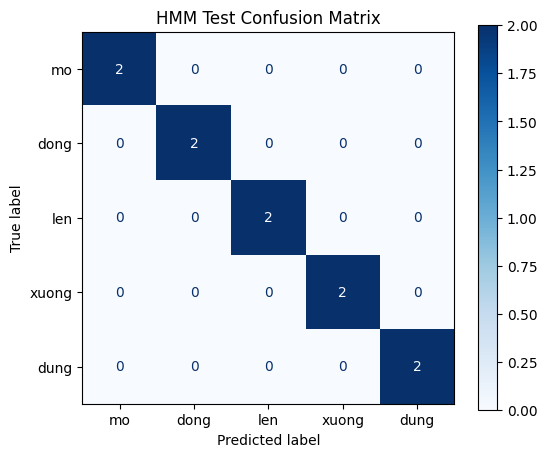


Bảng điểm chi tiết log-likelihood của 3 utterance kiểm thử:

File mo_07.wav (Nhãn đúng: 'mo', Dự đoán: 'mo', Gap top1-top2: 1077.73)
   Model 'mo    ':   -4953.05
   Model 'len   ':   -6030.78
   Model 'xuong ':   -6105.99
   Model 'dong  ':   -6216.88
   Model 'dung  ':   -6667.36

File len_08.wav (Nhãn đúng: 'len', Dự đoán: 'len', Gap top1-top2: 799.50)
   Model 'len   ':   -5917.87
   Model 'xuong ':   -6717.37
   Model 'mo    ':   -6812.50
   Model 'dong  ':   -7109.66
   Model 'dung  ':   -7162.56

File dung_08.wav (Nhãn đúng: 'dung', Dự đoán: 'dung', Gap top1-top2: 497.18)
   Model 'dung  ':   -6950.15
   Model 'dong  ':   -7447.33
   Model 'mo    ':   -8012.45
   Model 'xuong ':   -8142.80
   Model 'len   ':   -8174.58


In [6]:
def recognize(F, models):
    scores = {k: m.score(F) for k, m in models.items()}
    return max(scores, key=scores.get), scores

def evaluate(models, X, y):
    pred = [recognize(F, models)[0] for F in X]
    return accuracy_score(y, pred), pred

acc_tr, _ = evaluate(models, Xtr, ytr)
acc_te, pred_te = evaluate(models, Xte, yte)
print(f"HMM Train Accuracy : {acc_tr * 100:.2f}%")
print(f"HMM Test Accuracy  : {acc_te * 100:.2f}%")

fig, ax = plt.subplots(figsize=(6, 5))
cm_hmm = confusion_matrix(yte, pred_te, labels=LABELS)
ConfusionMatrixDisplay(cm_hmm, display_labels=LABELS).plot(cmap="Blues", ax=ax)
plt.title("HMM Test Confusion Matrix")
plt.savefig("figures/cm_hmm.png", dpi=130)
plt.show()

print("\nBảng điểm chi tiết log-likelihood của 3 utterance kiểm thử:")
for i in [0, len(Xte) // 2, len(Xte) - 1]:
    p, sc = recognize(Xte[i], models)
    srt = sorted(sc.items(), key=lambda z: -z[1])
    print(f"\nFile {nte[i]} (Nhãn đúng: '{yte[i]}', Dự đoán: '{p}', Gap top1-top2: {srt[0][1]-srt[1][1]:.2f})")
    for k, v in srt:
        print(f"   Model '{k:6s}': {v:10.2f}")


Viterbi mo_07.wav: Log-prob=-4953.49, Duration/state=[27, 8, 33, 7, 31], Đường đơn điệu=True
Viterbi dong_07.wav: Log-prob=-5499.06, Duration/state=[23, 8, 34, 25, 29], Đường đơn điệu=True


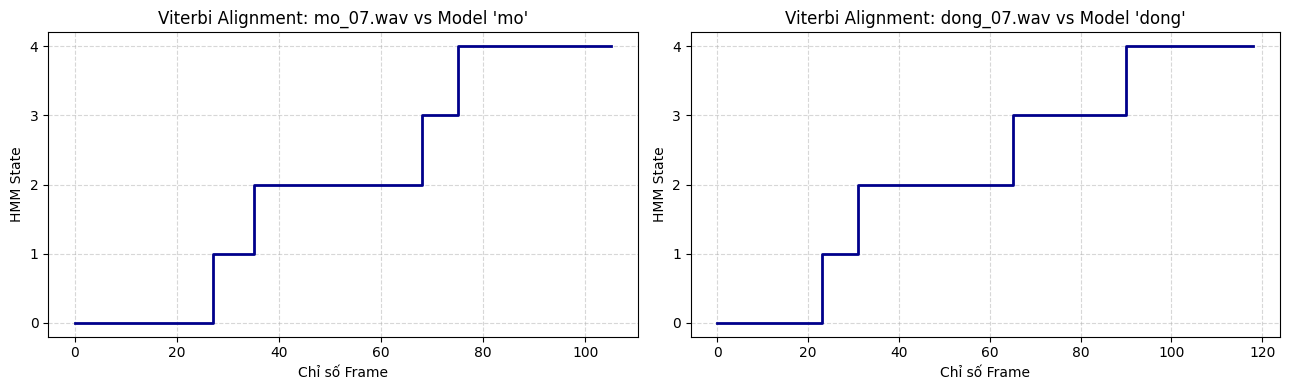

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
test_indices = [0, 2] # mo_07, dong_07
for idx, i in enumerate(test_indices):
    F, lab = Xte[i], yte[i]
    lp, st = models[lab].decode(F, algorithm="viterbi")
    ax[idx].step(range(len(st)), st, where="post", color="darkblue", lw=2)
    ax[idx].set_title(f"Viterbi Alignment: {nte[i]} vs Model '{lab}'")
    ax[idx].set_xlabel("Chỉ số Frame")
    ax[idx].set_ylabel("HMM State")
    ax[idx].set_yticks(range(5))
    ax[idx].grid(True, ls="--", alpha=0.5)
    dur = np.bincount(st, minlength=models[lab].n_components)
    print(f"Viterbi {nte[i]}: Log-prob={lp:.2f}, Duration/state={dur.tolist()}, Đường đơn điệu={bool(np.all(np.diff(st) >= 0))}")

plt.tight_layout()
plt.savefig("figures/viterbi.png", dpi=130)
plt.show()


## E. So sánh hiệu năng HMM với DTW Baseline (Lab 2)
- Chạy phương pháp đối sánh mẫu DTW (Dynamic Time Warping) với khoảng cách Euclidean trên ma trận 39 chiều.
- So sánh toàn diện: Độ chính xác, thời gian huấn luyện, thời gian nhận dạng (test time/trial) và tính hiệu quả khi ít dữ liệu.


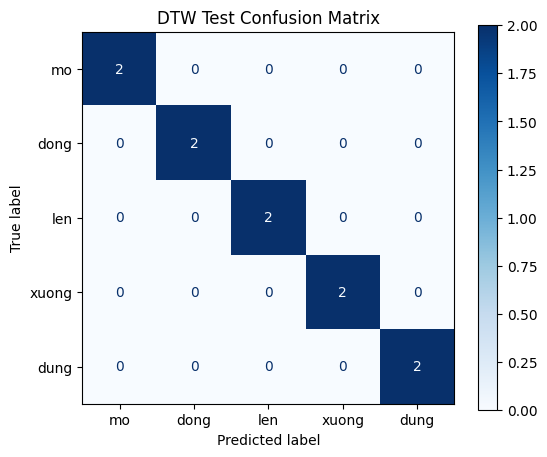

BẢNG SO SÁNH ĐỊNH LƯỢNG GIỮA DTW VÀ HMM:
| Tiêu chí | DTW Baseline | HMM |
|---|---|---|
| Accuracy | 100.0% | 100.0% |
| Thời gian train | ≈ 0 s (lưu template) | 0.13 s |
| Thời gian test/trial | 87.4 ms | 0.9 ms |
| Cơ chế alignment | Warping path trực tiếp | Viterbi state sequence |

- DTW với duy nhất 1 template/lớp : Accuracy = 100.0%
- HMM với 2 utterance/lớp (3 states): Accuracy = 100.0%


In [8]:
def dtw_cost(A, B):
    D, wp = librosa.sequence.dtw(X=A.T, Y=B.T, metric="euclidean")
    return D[-1, -1] / len(wp)

def dtw_predict(F, Xtr, ytr):
    best, lab = np.inf, None
    for T, l in zip(Xtr, ytr):
        c = dtw_cost(F, T)
        if c < best:
            best, lab = c, l
    return lab

t0 = time.time()
pred_dtw = [dtw_predict(F, Xtr, ytr) for F in Xte]
t_dtw_test = (time.time() - t0) / len(Xte)
acc_dtw = accuracy_score(yte, pred_dtw)

t0 = time.time()
_ = [recognize(F, models)[0] for F in Xte]
t_hmm_test = (time.time() - t0) / len(Xte)

fig, ax = plt.subplots(figsize=(6, 5))
cm_dtw = confusion_matrix(yte, pred_dtw, labels=LABELS)
ConfusionMatrixDisplay(cm_dtw, display_labels=LABELS).plot(cmap="Blues", ax=ax)
plt.title("DTW Test Confusion Matrix")
plt.savefig("figures/cm_dtw.png", dpi=130)
plt.show()

print("BẢNG SO SÁNH ĐỊNH LƯỢNG GIỮA DTW VÀ HMM:")
print(f"| Tiêu chí | DTW Baseline | HMM |")
print(f"|---|---|---|")
print(f"| Accuracy | {acc_dtw*100:.1f}% | {acc_te*100:.1f}% |")
print(f"| Thời gian train | ≈ 0 s (lưu template) | {t_hmm_train:.2f} s |")
print(f"| Thời gian test/trial | {t_dtw_test*1000:.1f} ms | {t_hmm_test*1000:.1f} ms |")
print(f"| Cơ chế alignment | Warping path trực tiếp | Viterbi state sequence |")

# Thí nghiệm ít mẫu
first = {}
for F, l in zip(Xtr, ytr):
    first.setdefault(l, F)
p1 = [dtw_predict(F, list(first.values()), list(first.keys())) for F in Xte]
print(f"\n- DTW với duy nhất 1 template/lớp : Accuracy = {accuracy_score(yte, p1)*100:.1f}%")

sub_X, sub_y, cnt = [], [], Counter()
for F, l in zip(Xtr, ytr):
    if cnt[l] < 2:
        sub_X.append(F); sub_y.append(l); cnt[l] += 1
m2 = train_models(sub_X, sub_y, 3)
a2, _ = evaluate(m2, Xte, yte)
print(f"- HMM với 2 utterance/lớp (3 states): Accuracy = {a2*100:.1f}%")


## F. Xây dựng Lexicon Mini
- Định dạng chuẩn: `WORD PHONE_1 PHONE_2 ... PHONE_K`.
- Cung cấp cơ chế mở rộng khi chuyển từ Whole-word HMM sang Subword/Phone HMM (ghép chuỗi HMM theo từ điển phát âm).


In [9]:
def write_lexicon():
    lex = {"mo": "m o", "dong": "d o ng", "len": "l e n", "xuong": "x uo ng", "dung": "d u ng"}
    with open("lexicon.txt", "w", encoding="utf-8") as f:
        for w, p in lex.items():
            f.write(f"{w} {p}\n")

def read_lexicon(path="lexicon.txt"):
    d = {}
    for line in open(path, encoding="utf-8"):
        parts = line.split()
        if parts:
            d[parts[0]] = parts[1:]
    return d

write_lexicon()
lex_dict = read_lexicon()
print("Từ điển phát âm Lexicon (lexicon.txt):")
for w, phones in lex_dict.items():
    print(f"  {w:8s} -> {' '.join(phones)}")


Từ điển phát âm Lexicon (lexicon.txt):
  mo       -> m o
  dong     -> d o ng
  len      -> l e n
  xuong    -> x uo ng
  dung     -> d u ng


## G. Mô hình ngôn ngữ Bigram & MAP Re-ranking
- Công thức đánh giá kết hợp: $\text{Score}(W) = \log P_A(X|W) + \lambda_{LM} \log P_L(W)$.
- Add-k smoothing ($k=0.5$): $P(w_j|w_i) = \frac{C(w_i, w_j) + k}{C(w_i) + kV}$.
- Khảo sát các mức trọng số $\lambda_{LM} \in \{0, 0.1, 0.3, 1.0, 3.0\}$.


In [10]:
CORPUS = ["mo len", "mo dong", "len dung", "xuong dung", "dong len", "len xuong",
          "xuong dong", "dung mo", "mo len dung", "dong xuong dung", "len dung", "xuong dung"]

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(CORPUS))

def build_counts(corpus):
    c1, c2 = Counter(), Counter()
    for s in corpus:
        w = ["<s>"] + s.split()
        c1.update(w[:-1])
        c2.update(zip(w[:-1], w[1:]))
    return c1, c2

def bigram_prob(prev, cur, c2, c1, V, k=0.5):
    return (c2.get((prev, cur), 0) + k) / (c1.get(prev, 0) + k * V)

def rerank(F, prev, models, c2, c1, lm_weight):
    T = len(F)
    tot = {w: m.score(F) / T + lm_weight * math.log(bigram_prob(prev, w, c2, c1, len(models)))
           for w, m in models.items()}
    return max(tot, key=tot.get), tot

c1, c2 = build_counts(CORPUS)

# Tìm utterance có top1-top2 gap nhỏ nhất
gaps = []
for i, F in enumerate(Xte):
    _, sc = recognize(F, models)
    s = sorted(sc.values(), reverse=True)
    gaps.append((s[0] - s[1]) / len(F))
i_min = int(np.argmin(gaps))
print(f"Mẫu có gap nhỏ nhất: {nte[i_min]} (Nhãn đúng: '{yte[i_min]}', gap/frame = {gaps[i_min]:.3f})\n")

print("Kết quả MAP Re-ranking với các giá trị λ_LM:")
header = f"{'prev':6s} | " + " | ".join([f"λ={lw}" for lw in (0, 0.1, 0.3, 1.0, 3.0)])
print(header)
print("-" * len(header))
for prev in ["<s>"] + LABELS:
    row = [f"{rerank(Xte[i_min], prev, models, c2, c1, lw)[0]:6s}" for lw in (0, 0.1, 0.3, 1.0, 3.0)]
    print(f"{prev:6s} | " + " | ".join(row))


Mẫu có gap nhỏ nhất: dong_08.wav (Nhãn đúng: 'dong', gap/frame = 0.612)

Kết quả MAP Re-ranking với các giá trị λ_LM:
prev   | λ=0 | λ=0.1 | λ=0.3 | λ=1.0 | λ=3.0
--------------------------------------------
<s>    | dong   | dong   | dong   | dong   | dong  
mo     | dong   | dong   | dong   | dong   | dong  
dong   | dong   | dong   | dong   | dong   | dong  
len    | dong   | dong   | dong   | dung   | dung  
xuong  | dong   | dong   | dong   | dung   | dung  
dung   | dong   | dong   | dong   | dong   | dong  


## H. Đánh giá Robustness với Nhiễu & Ngưỡng Reject (Từ chối từ lạ)
- Thử nghiệm mismatch với các mức nhiễu trắng SNR: 20 dB, 10 dB, 5 dB.
- Phân tích phân phối Log-likelihood/frame của các cặp đúng lớp (Target) và sai lớp (Non-target).
- Đề xuất ngưỡng Reject tại phân vị thứ 5 (5th percentile) của lớp đúng.


Thử nghiệm môi trường nhiễu trắng (Mismatch SNR):


  SNR = 20 dB: HMM Accuracy = 100.0% | DTW Accuracy = 100.0%


  SNR = 10 dB: HMM Accuracy = 100.0% | DTW Accuracy = 100.0%


  SNR =  5 dB: HMM Accuracy = 90.0% | DTW Accuracy = 100.0%


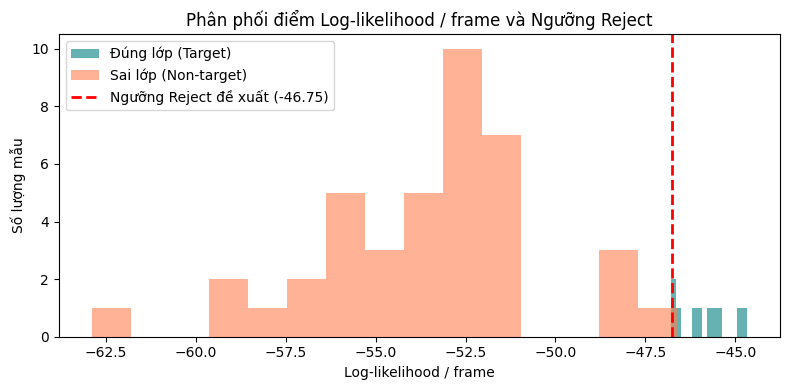

Ngưỡng Reject đề xuất (5th percentile đúng lớp): -46.75
Điểm trung bình đúng lớp: -45.84 | Điểm trung bình sai lớp: -53.45


In [11]:
print("Thử nghiệm môi trường nhiễu trắng (Mismatch SNR):")
for snr in (20, 10, 5):
    Xn, yn, _ = load_split("test", noise_snr=snr)
    an, _ = evaluate(models, Xn, yn)
    ad = accuracy_score(yn, [dtw_predict(F, Xtr, ytr) for F in Xn])
    print(f"  SNR = {snr:2d} dB: HMM Accuracy = {an*100:.1f}% | DTW Accuracy = {ad*100:.1f}%")

right, wrong = [], []
for F, l in zip(Xte, yte):
    _, sc = recognize(F, models)
    T = len(F)
    right.append(sc[l] / T)
    wrong += [v / T for k, v in sc.items() if k != l]

plt.figure(figsize=(8, 4))
plt.hist(right, bins=15, alpha=0.6, label="Đúng lớp (Target)", color="teal")
plt.hist(wrong, bins=15, alpha=0.6, label="Sai lớp (Non-target)", color="coral")
thr = np.percentile(right, 5)
plt.axvline(thr, color="red", ls="--", lw=2, label=f"Ngưỡng Reject đề xuất ({thr:.2f})")
plt.xlabel("Log-likelihood / frame")
plt.ylabel("Số lượng mẫu")
plt.title("Phân phối điểm Log-likelihood / frame và Ngưỡng Reject")
plt.legend()
plt.tight_layout()
plt.savefig("figures/score_dist.png", dpi=130)
plt.show()

print(f"Ngưỡng Reject đề xuất (5th percentile đúng lớp): {thr:.2f}")
print(f"Điểm trung bình đúng lớp: {np.mean(right):.2f} | Điểm trung bình sai lớp: {np.mean(wrong):.2f}")


## I. Các thí nghiệm mở rộng (E1, E2, E3)
- **E1**: Khảo sát số trạng thái HMM: $n\_states \in \{3, 5, 7\}$.
- **E2**: Khảo sát đặc trưng: 13-D MFCC tĩnh vs 39-D MFCC động (MFCC + $\Delta$ + $\Delta^2$).
- **E3**: Khảo sát ma trận hiệp phương sai: Diagonal Covariance vs Full Covariance.


=== E1. Khảo sát số trạng thái n_states in {3, 5, 7} ===
  n_states = 3: Test Accuracy = 100.0% | Số mô hình hội tụ = 5/5


  n_states = 5: Test Accuracy = 100.0% | Số mô hình hội tụ = 5/5


  n_states = 7: Test Accuracy = 100.0% | Số mô hình hội tụ = 5/5

=== E2. Khảo sát đặc trưng 13-D vs 39-D ===


Model is not converging.  Current: -8520.75358543973 is not greater than -8520.753560338842. Delta is -2.5100887796725146e-05


  Đặc trưng 13-D tĩnh: Accuracy = 100.0%
  Đặc trưng 39-D động : Accuracy = 100.0%


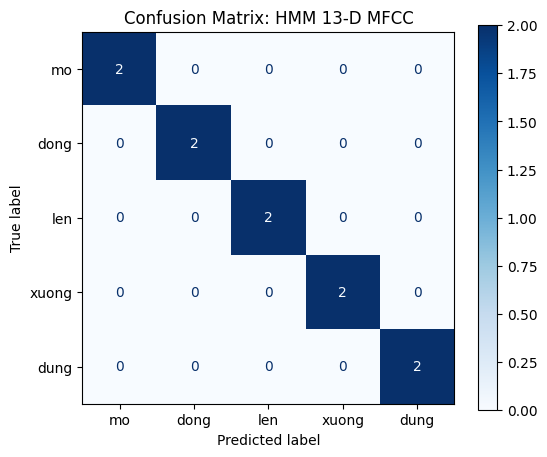


=== E3. Khảo sát Diagonal vs Full Covariance ===


  Full Covariance: Train Acc = 100.0% | Test Acc = 100.0%
  Diag Covariance: Train Acc = 100.0% | Test Acc = 100.0%


In [12]:
print("=== E1. Khảo sát số trạng thái n_states in {3, 5, 7} ===")
for n in (3, 5, 7):
    ms = train_models(Xtr, ytr, n)
    a, _ = evaluate(ms, Xte, yte)
    conv = sum(m.monitor_.converged for m in ms.values())
    print(f"  n_states = {n}: Test Accuracy = {a*100:.1f}% | Số mô hình hội tụ = {conv}/5")

print("\n=== E2. Khảo sát đặc trưng 13-D vs 39-D ===")
X13tr, _, _ = load_split("train", dynamic=False)
X13te, _, _ = load_split("test", dynamic=False)
m13 = train_models(X13tr, ytr, 5, dynamic=False)
a13, p13 = evaluate(m13, X13te, yte)
print(f"  Đặc trưng 13-D tĩnh: Accuracy = {a13*100:.1f}%")
print(f"  Đặc trưng 39-D động : Accuracy = {acc_te*100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 5))
cm13 = confusion_matrix(yte, p13, labels=LABELS)
ConfusionMatrixDisplay(cm13, display_labels=LABELS).plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix: HMM 13-D MFCC")
plt.savefig("figures/cm_hmm13.png", dpi=130)
plt.show()

print("\n=== E3. Khảo sát Diagonal vs Full Covariance ===")
try:
    mf = train_models(Xtr, ytr, 5, cov="full")
    atr_f, _ = evaluate(mf, Xtr, ytr)
    ate_f, _ = evaluate(mf, Xte, yte)
    print(f"  Full Covariance: Train Acc = {atr_f*100:.1f}% | Test Acc = {ate_f*100:.1f}%")
    print(f"  Diag Covariance: Train Acc = {acc_tr*100:.1f}% | Test Acc = {acc_te*100:.1f}%")
except Exception as e:
    print("  Huấn luyện Full Covariance thất bại:", e)


## K. Trả lời chi tiết 10 câu hỏi phân tích lý thuyết (Mục 6.1)

1. **Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?**
   - *Phép toán:* Forward sử dụng phép cộng tổng xác suất trên mọi đường đi trạng thái hợp lệ ($\sum$). Viterbi thay phép cộng bằng phép lấy cực đại ($\max$) kèm mảng lưu vết back-pointer ($\psi$).
   - *Câu hỏi trả lời:* Forward trả lời: *"Mô hình $\lambda$ sinh ra chuỗi quan sát $X$ với tổng xác suất likelihood bằng bao nhiêu? ($P(X|\lambda)$)"*. Viterbi trả lời: *"Đường đi trạng thái đơn lẻ tốt nhất (tối ưu nhất) sinh ra chuỗi quan sát $X$ là gì? ($Q^* = \arg\max_Q P(X, Q|\lambda)$)"*, đồng thời cung cấp alignment giữa từng frame âm thanh và từng trạng thái.

2. **Giải thích $\gamma_t(i)$ và $\xi_t(i,j)$ bằng ngôn ngữ “trách nhiệm” trong EM:**
   - Trong thuật toán EM (Baum-Welch):
     - $\gamma_t(i) = P(q_t = S_i | X, \lambda)$ là mức độ *"chịu trách nhiệm"* của trạng thái $i$ trong việc phát xạ ra vector đặc trưng tại khung thời gian $t$. Giá trị này được dùng làm trọng số để ước lượng lại vector trung bình $\mu_i$ và ma trận hiệp phương sai $\Sigma_i$.
     - $\xi_t(i,j) = P(q_t = S_i, q_{t+1} = S_j | X, \lambda)$ là mức độ *"chịu trách nhiệm"* của bước chuyển trạng thái từ $i$ sang $j$ giữa thời điểm $t$ và $t+1$. Tỷ số giữa $\sum_t \xi_t(i,j)$ và $\sum_t \gamma_t(i)$ cho xác suất chuyển tiếp mới $a_{ij}$.

3. **Tại sao Baum-Welch có thể hội tụ đến nghiệm xấu? Liệt kê ít nhất ba nguyên nhân thực nghiệm:**
   - Thuật toán Baum-Welch là một trường hợp của EM, chỉ đảm bảo hội tụ về cực trị cục bộ (local optimum) chứ không đảm bảo cực trị toàn cục.
   - Ba nguyên nhân thực nghiệm:
     - *Khởi tạo ban đầu kém:* Nếu dùng K-means không có thứ tự thời gian (như đã thấy thực nghiệm làm 3/5 model bị NaN, accuracy tụt xuống 20%). Flat start giải quyết được vấn đề này.
     - *Dữ liệu huấn luyện quá ít:* Số tham số cần ước lượng lớn hơn nhiều so với số khung quan sát thực tế dẫn đến suy biến ma trận hiệp phương sai (variance collapse).
     - *Cấu hình siêu tham số không phù hợp:* Số trạng thái quá lớn khiến một số trạng thái không nhận được frame nào.

4. **Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?**
   - Với không gian 39 chiều, ma trận Diagonal chỉ cần ước lượng 39 tham số (phương sai từng chiều), trong khi Full Covariance cần tới $39 \times 40 / 2 = 780$ tham số cho mỗi trạng thái.
   - Khi dữ liệu ít, Full Covariance rất dễ bị quá khớp (overfitting) hoặc ma trận bị suy biến (singular/non-invertible).
   - Biến đổi DCT trong MFCC đã khử tương quan đáng kể giữa các hệ số nên giả thiết độc lập giữa các chiều (ma trận đường chéo) là hoàn toàn hợp lý và ổn định.

5. **Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?**
   - HMM chuẩn có giả thiết ngầm là *output independence*: xác suất phát xạ $b_i(x_t)$ tại khung $t$ chỉ phụ thuộc vào trạng thái hiện tại $q_t$, hoàn toàn độc lập với các khung lân cận $x_{t-1}, x_{t+1}$.
   - Việc bổ sung $\Delta$ (vận tốc biến thiên phổ) và $\Delta^2$ (gia tốc biến thiên phổ) đã nhúng trực tiếp thông tin ngữ cảnh thời gian lân cận vào từng vector frame mà không làm tăng bậc Markov của mô hình.

6. **Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?**
   - Whole-word HMM không cần lexicon khi bài toán nhận dạng là tập từ vựng đóng (closed vocabulary), quy mô nhỏ (ví dụ vài lệnh điều khiển) và mỗi từ có đủ dữ liệu thu âm riêng để huấn luyện một model độc lập.
   - Lexicon trở thành bắt buộc khi:
     - Hệ thống mở rộng sang nhận dạng từ vựng lớn (LVCSR) hoặc tiếng nói liên tục (Continuous Speech Recognition).
     - Hệ thống xây dựng trên các đơn vị âm vị học nhỏ hơn (subword/phone HMM), đòi hỏi từ điển phát âm ánh xạ từ chuỗi âm vị (phone) sang từ (word).

7. **Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?**
   - Vòng tự lặp (self-loop $a_{ii}$) cho phép mô hình lưu lại ở cùng một trạng thái trong nhiều khung thời gian liên tiếp.
   - Khi người nói phát âm chậm hoặc kéo dài nguyên âm, số frame tăng lên sẽ được hấp thu tự nhiên bởi self-loop (duration ngầm tuân theo phân phối hình học) mà không làm phá vỡ tiến trình tuần tự sang các trạng thái kế tiếp.

8. **Với cùng một utterance, có cần chia log-likelihood cho $T$ để chọn model tốt nhất không? Tại sao?**
   - *Không cần thiết* khi chỉ so sánh giữa các mô hình trên cùng một utterance, vì chiều dài $T$ là hoàn toàn như nhau đối với tất cả các mô hình, nên phép chia cho hằng số dương $T$ không làm thay đổi vị trí cực đại $\arg\max$.
   - Tuy nhiên, việc chia cho $T$ (tính $\bar{s} = \frac{\log P(X|\lambda)}{T}$) là *bắt buộc* khi cần so sánh độ tin cậy hoặc thiết lập ngưỡng reject (từ chối từ lạ) giữa các utterance có độ dài khác nhau.

9. **So sánh warping path của DTW với state path của Viterbi:**
   - *Warping path của DTW:* Là phép gióng hàng trực tiếp giữa 2 chuỗi frame cụ thể (mẫu thử và mẫu chuẩn template), chi phí tối ưu hóa là khoảng cách hình học Euclidean trong không gian đặc trưng.
   - *State path của Viterbi:* Là phép gióng hàng xác suất giữa chuỗi frame quan sát với một chuỗi các trạng thái thống kê trừu tượng của mô hình Markov, chi phí tối ưu hóa là xác suất log-likelihood tích lũy.

10. **Nếu hệ thống gặp một từ ngoài vocabulary, tại sao argmax vẫn bắt buộc chọn một lớp? Hãy đề xuất reject criterion:**
    - Hàm $\arg\max$ chỉ thực hiện so sánh tương đối giữa các giá trị điểm số của các lớp có sẵn, do đó luôn chọn ra lớp có điểm cao nhất dù điểm số đó rất thấp so với một phát âm chuẩn.
    - *Tiêu chuẩn Reject đề xuất:*
      1. Đặt ngưỡng log-likelihood chuẩn hóa trên mỗi frame: Nếu $\frac{\log P(X|\lambda_{\text{best}})}{T} < \theta_{\text{reject}}$ (ví dụ ngưỡng percentile thứ 5 của tập train), từ chối nhận dạng và trả về "unknown".
      2. Đặt ngưỡng chênh lệch điểm (Top-1 / Top-2 Gap): Nếu hiệu số giữa mô hình tốt nhất và mô hình thứ nhì chia cho $T$ nhỏ hơn một ngưỡng $\delta_{\text{min}}$, từ chối đưa ra quyết định do độ tin cậy thấp.
